[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/steeve-g/notebooks/14_retina_envelope_spectrum.ipynb)

# Retina: envelope spectrum

* **Author**: laquitainesteeve@gmail.com

* **Goal**: Task 3 of the note *Scale-resolved decomposition of G(x)* for the retina, as notebook 9 for V1 and V4: plot the envelope spectrum $\rho^{\rm env}(\tau) = \mathbb{E}\left[\frac1t \lVert \hat x(x_t) - x \rVert^2\right]$ against $\tau = \log t$ on 200 test images, the error of the unconditional denoiser of the retina diffusion models per unit of noise variance, with the Gaussian bound of their training images.

* **Requirements**: TinyImageNet, the retina checkpoints (downloaded below), a GPU, `multigeom` from the `g-per-scale` branch and `openretina` from the private repository `open-retina-multigeom`.

* **Time**: about 15 min on a GPU.

## 1. Setup

### 1.1. Install package

Install the version of `multigeom` this notebook needs, the `g-per-scale` branch on GitHub, and, on Google Colab, `openretina` from the private repository `open-retina-multigeom` (with a GitHub token stored in Colab's secrets as `GH_TOKEN`). Elsewhere, `multigeom` is installed only if the installed one lacks its functions, and `openretina` as the README of `tests/fixtures/retina/` says.

In [1]:
%%time

# the multigeom this notebook needs: the g-per-scale branch on GitHub, until it is
# released (without its dependencies: Colab already has torch, numpy, scipy and
# matplotlib, and reinstalling torch is slow and can break the GPU runtime)
import os
import sys

BRANCH = "git+https://github.com/multigeom/multigeom.git@g-per-scale"

# on Google Colab: install the latest commit of that branch (forced: pip skips a
# branch it installed before, even if the branch has changed since), and the
# diffusion models' library
if "google.colab" in sys.modules:
    %pip install -q --no-deps --force-reinstall {BRANCH}
    %pip install -q "diffusers>=0.30,<0.38"

    # an older multigeom imported earlier in this session stays in memory: restart
    # the session so that the next cells import the new one (then run them from the
    # next cell on)
    # open-retina with Baptiste Lorenzi's retina models: the private repository
    # open-retina-multigeom, with a GitHub token in Colab's secrets (GH_TOKEN)
    from google.colab import userdata

    TOKEN = userdata.get("GH_TOKEN")
    RETINA = "github.com/steevelaquitaine/open-retina-multigeom.git"
    %pip install -q --no-deps "git+https://{TOKEN}@{RETINA}"
    DEPENDENCIES = (
        "jaxtyping hydra-core lightning tenacity opencv-python-headless seaborn"
    )
    %pip install -q {DEPENDENCIES} moviepy

    if "multigeom" in sys.modules:
        print("restarting the session to load the new multigeom: run the next cells")
        os.kill(os.getpid(), 9)

# on your own machine: install that branch only if the installed multigeom lacks its
# functions (this replaces an editable install; restart the kernel afterwards)
else:
    import multigeom

    if not hasattr(multigeom.analysis, "compute_bootstrap"):
        %pip install -q --no-deps {BRANCH}
        print("installed multigeom from the g-per-scale branch: restart the kernel")

CPU times: user 3.14 s, sys: 76.1 ms, total: 3.21 s
Wall time: 613 ms


### 1.2. Imports and parameters

Work from the repository root, import the packages, and set the parameters: the models, the test images, the noise scales, and where the results and the figure go.

<details><summary>Details</summary>

* `load_retina` loads a cell's models (notebook 12); `load_retina_test_images` loads test images in the diffusion model's units; `compute_retina_prior_variances` gives the variances of the models' training images along their principal components, from which `compute_gaussian_env` makes the Gaussian bound; `plot_env_spectrum` draws the figure. The spectrum itself is `multigeom.compute_env_spectrum`, as in notebook 9.

</details>

In [2]:
%%time

import os
from pathlib import Path

from huggingface_hub import snapshot_download

# move to the repository root (the folder containing environment.yml): data/, runs/
# and assets/ are read and written from there
root = Path.cwd().resolve()
while not (root / "environment.yml").exists() and root != root.parent:
    root = root.parent

if (root / "environment.yml").exists():
    os.chdir(root)

print("repo root:", root)

from multigeom import compute_env_spectrum
from multigeom.config import load_config
from multigeom.datasets import download_tinyimagenet
from multigeom.encoders.retina import (
    compute_retina_prior_variances,
    load_retina,
    load_retina_test_images,
)
from multigeom.geometry import compute_gaussian_env
from multigeom.plotting import plot_env_spectrum
from multigeom.utils import get_device, load_intermediate, make_generator
from multigeom.utils import save_intermediate

# the parameters of this notebook
PARAMS = {
    # the models whose null token gives the unconditional model: W3, as in notebook
    # 13, and tOFFalpha as a check (runs/<stage>/lorenzi/<area>/)
    "encoder": "lorenzi",
    "cell_types": {"W3": "retina-W3_176-exp7", "tOFFalpha": "retina-tOFFalpha_17-exp5"},
    # the test images: TinyImageNet training images 50,000 to 50,199 in open-retina's
    # shuffled order (the first 6 are those of notebooks 12 and 13), standardised
    # together as open-retina does
    "n_test_images": 200,
    "frames": "data/tiny-imagenet-200/train",
    "normalizer": "data/02_intermediate/retina/normalizer.pt",
    # the noisy versions of each image at each noise scale, and how many the network
    # sees at once (100 fit in the GPU's memory at 120 x 120)
    "n_noise": 8,
    "batch_size": 100,
    # the DDPM steps of notebook 9: the 24 of the paper (40 to 960), and more at both
    # ends
    "timesteps": [1, 2, 5, 10, 20, *range(40, 961, 40), 980, 999],
    # where the computed results are stored, so that a new run reloads them in seconds
    # (True: recompute and overwrite them)
    "intermediate_dir": "data/02_intermediate/14_retina_envelope_spectrum",
    "recompute": False,
    # where the figure is saved, and its resolution in the file and on screen
    "figure_dir": "assets/figures/retina/task3",
    "file_dpi": 200,
    "screen_dpi": 100,
}

# the estimator config (packaged with multigeom)
est_cfg = load_config("estimator")

# compute device
device = get_device(None)
print("device:", device)

repo root: /home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials


device: cuda
CPU times: user 697 ms, sys: 92 ms, total: 789 ms
Wall time: 799 ms


## 2. Download the retina models

The checkpoints of the two cells are on Hugging Face, with those of V1 and V4; only the retina ones are downloaded.

In [3]:
%%time

# download the retina checkpoints into runs/ (files that are already there are kept)
snapshot_download(
    repo_id="steevelaquitaine/multigeom", local_dir="runs", allow_patterns="*/lorenzi/*"
)

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

CPU times: user 34.6 ms, sys: 3.08 ms, total: 37.7 ms
Wall time: 439 ms


'/home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials/runs'

## 3. Download datasets

TinyImageNet gives the test images and the training images of the Gaussian bound (240 MB the first time).

In [4]:
%%time

# TinyImageNet (nothing if already there)
download_tinyimagenet()

CPU times: user 170 μs, sys: 0 ns, total: 170 μs
Wall time: 221 μs


PosixPath('/home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials/data/tiny-imagenet-200')

## 4. Compute the envelope spectrum and the Gaussian bound

For each test image and noise scale, the error of the unconditional denoiser (the null token of each cell's diffusion model) on noisy versions of the image, per unit of noise variance; its mean over the images is $\rho^{\rm env}(\tau)$. Then the Gaussian bound, from the models' training images.

<details><summary>Details</summary>

* **Definition** (the note, eq. 6), computed as in notebook 9: by Tweedie's formula $\frac1t \lVert \hat x - x \rVert^2 = \lVert \hat\epsilon - \epsilon \rVert^2$, summed over the $P = 14{,}400$ pixels of the 120 x 120 images, in the diffusion model's units.
* **Gaussian bound.** $\sum_i c_i / (c_i + t)$, with $c_i$ the variances along the principal components of the 15,000 TinyImageNet training images the models' image units were fitted to: the error of the best linear denoiser. At fine scales it tends to the number of pixels, at coarse scales to $\mathrm{tr}\,C / t$.
* **Stored results.** The spectra and the variances are stored in `data/02_intermediate/14_retina_envelope_spectrum/`; later runs reload them.

</details>

In [5]:
%%time

# the results, reloaded if stored, else computed and stored
results_file = Path(PARAMS["intermediate_dir"]) / "results.pt"
if results_file.exists() and not PARAMS["recompute"]:
    spectra, variances = load_intermediate(results_file)
else:
    spectra, frames = {}, Path(PARAMS["frames"])
    for cell_type, area in PARAMS["cell_types"].items():
        # the cell's models, and the test images in the diffusion model's units
        models = load_retina(
            area, Path("runs"), frames, device, normalizer_cache=PARAMS["normalizer"]
        )
        images = load_retina_test_images(models, frames, n=PARAMS["n_test_images"])

        # the error of the null token on noisy versions of every image
        spectra[cell_type] = compute_env_spectrum(
            images,
            models.unet,
            models.alphas_cumprod,
            PARAMS["timesteps"],
            device,
            n_noise=PARAMS["n_noise"],
            batch_size=PARAMS["batch_size"],
            generator=make_generator(int(est_cfg.seed), device),
        )
        print(cell_type, "done:", tuple(spectra[cell_type].values.shape))

    # the variances of the training images (the same for both models)
    variances = compute_retina_prior_variances(models, frames, device)
    save_intermediate((spectra, variances), results_file)

# the Gaussian bound at the noise scales of the spectrum
gaussian = compute_gaussian_env(variances, spectra["W3"].log_tau)
print(f"P = {len(variances)} pixels, total variance tr C = {variances.sum():.0f}")

/home/steeve/miniconda3/envs/tutorials-env/lib/python3.11/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'core' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['core'])`.
/home/steeve/miniconda3/envs/tutorials-env/lib/python3.11/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'readout' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['readout'])`.


W3 done: (200, 31)


tOFFalpha done: (200, 31)


P = 14400 pixels, total variance tr C = 1587
CPU times: user 5min 30s, sys: 6.59 s, total: 5min 37s
Wall time: 5min 26s


## 5. Plot the envelope spectrum

$\rho^{\rm env}(\tau)$ of the W3 model, the mean over the test images, with the spread of the images and the Gaussian bound. The figure is also saved to `assets/figures/retina/task3/envelope_spectrum.png`; the cell prints the values the conclusion uses, including those of the tOFFalpha model, which is not drawn.

 tau |      W3 | tOFFalpha | Gaussian bound | tr C / t
 -8.4 | 4.07e+03 |  4.16e+03 |       4.15e+03 | 7.21e+06
 -7.9 | 3.71e+03 |  3.78e+03 |       4.03e+03 | 4.41e+06
 -7.0 | 3.15e+03 |   3.2e+03 |       3.78e+03 | 1.76e+06
 -6.1 | 2.65e+03 |  2.69e+03 |       3.43e+03 | 7.22e+05
 -5.1 | 2.06e+03 |  2.09e+03 |       2.82e+03 | 2.52e+05
 -3.9 | 1.43e+03 |  1.44e+03 |       1.99e+03 | 7.68e+04
 -2.6 |     846 |       850 |       1.16e+03 | 2.1e+04
 -1.8 |     572 |       574 |            763 | 9.34e+03
 -1.2 |     413 |       413 |            539 | 5.06e+03
 -0.6 |     311 |       311 |            396 | 3.03e+03
 -0.2 |     238 |       238 |            298 | 1.92e+03
  0.2 |     185 |       185 |            227 | 1.26e+03
  0.6 |     145 |       145 |            174 | 844
  1.0 |     113 |       113 |            133 | 568
  1.4 |    87.9 |      87.6 |            101 | 381
  1.8 |    67.7 |      67.4 |           75.6 | 253
  2.3 |    51.5 |      51.4 |           55.9 | 166
  2.7 |    38

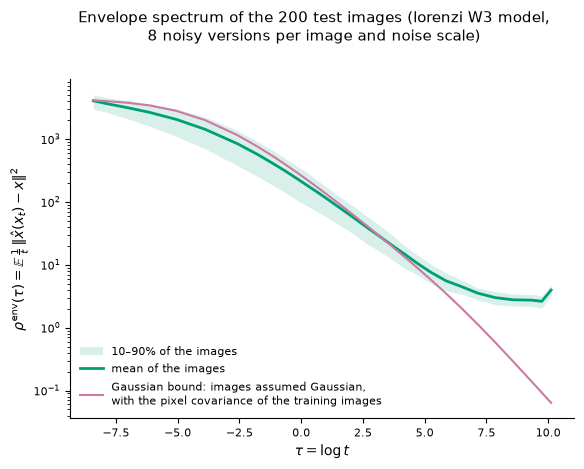

In [6]:
%%time

# 1. the figure, also saved
figure_dir = Path(PARAMS["figure_dir"])
figure_dir.mkdir(parents=True, exist_ok=True)
fig, plotted = plot_env_spectrum(spectra, gaussian, PARAMS)
fig.savefig(
    figure_dir / "envelope_spectrum.png", dpi=PARAMS["file_dpi"], bbox_inches="tight"
)

# 2. the values at each noise scale, against the Gaussian bound and its coarse limit
log_t, w3, bound = plotted["log_t"], plotted["mean"], plotted["gaussian"]
coarse_limit = (variances.sum() / spectra["W3"].log_tau.double().exp()).numpy()
toff = spectra["tOFFalpha"].values.double().mean(dim=0).numpy()
print(" tau |      W3 | tOFFalpha | Gaussian bound | tr C / t")
for level in range(len(log_t)):
    print(
        f"{log_t[level]:5.1f} | {w3[level]:7.3g} | {toff[level]:9.3g} |"
        f" {bound[level]:14.3g} | {coarse_limit[level]:.3g}"
    )

## 6. Conclusion

* **What we computed.** The envelope spectrum $\rho^{\rm env}(\tau)$ of 200 test images at 31 noise scales, from the null tokens of the W3 and tOFFalpha retina diffusion models (about 5 min for both), with the Gaussian bound of their 15,000 training images (P = 14,400 pixels, tr C = 1587). The figure is in `assets/figures/retina/task3/`.
* **Fine and middle scales behave as for V1 and V4.** The curve starts near the number of pixels (4070 at $\tau = -8.4$, bound 4150) and stays below the Gaussian bound up to $\tau \approx 3.2$, at 0.70–0.85 times the bound around $\tau = -6$ to $-2$. The two models agree within 2% there.
* **At coarse scales the curve measures the networks, not the images.** From $\tau \approx 3.6$ it lies above the Gaussian bound, which no exact posterior mean can do, and it flattens at about 2.6–4 instead of falling like $\mathrm{tr}\,C/t$ (0.064 at $\tau = 10.1$): 40–60 times the bound at the coarsest scales, against 1.7 times for V1 (notebook 9). About 1 of it comes from the models keeping the overall brightness of the noisy image (notebook 13: the denoiser passes about 95% of it through at every scale); the rest is an error floor of the networks. Anything computed from these networks at $\tau \gtrsim 4$, such as the coding spectrum of task 4, inherits it.
* **Next steps.** Find why the retina models keep the brightness of the noisy image (their training images or preprocessing), then task 4 for the retina.